## 1. Data Loading

Loads FER-2013 from the pickled `.pt` files (JPEG-encoded 48x48
grayscale images + string emotion labels) and verifies shapes/labels.

In [1]:
import pickle
import io
import os
import numpy as np
from PIL import Image

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
LABEL_TO_IDX = {name: i for i, name in enumerate(EMOTIONS)}


def load_split(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} not found. Download it first — see README.md 'Data' section "
            f"or docs/adr/0001-fer-capstone-stack.md."
        )
    with open(path, "rb") as f:
        records = pickle.load(f)

    images = np.zeros((len(records), 48, 48), dtype=np.uint8)
    labels = np.zeros(len(records), dtype=np.int64)
    for i, rec in enumerate(records):
        assert "img_bytes" in rec and "labels" in rec, f"record {i} missing expected keys"
        img = Image.open(io.BytesIO(rec["img_bytes"])).convert("L")
        assert img.size == (48, 48), f"record {i} has unexpected size {img.size}"
        images[i] = np.array(img, dtype=np.uint8)
        assert rec["labels"] in LABEL_TO_IDX, f"record {i} has unknown label {rec['labels']!r}"
        labels[i] = LABEL_TO_IDX[rec["labels"]]
    return images, labels

In [2]:
train_images, train_labels = load_split("data/train.pt")
test_images, test_labels = load_split("data/test.pt")

print("train:", train_images.shape, train_labels.shape)
print("test:", test_images.shape, test_labels.shape)
assert train_images.shape == (28709, 48, 48)
assert test_images.shape == (7178, 48, 48)
assert train_images.dtype == np.uint8
assert set(np.unique(train_labels)) == set(range(7))

import collections
print("train label counts:", collections.Counter(train_labels.tolist()))
print("test label counts:", collections.Counter(test_labels.tolist()))

train: (28709, 48, 48) (28709,)
test: (7178, 48, 48) (7178,)
train label counts: Counter({3: 7215, 4: 4965, 5: 4830, 2: 4097, 0: 3995, 6: 3171, 1: 436})
test label counts: Counter({3: 1774, 5: 1247, 4: 1233, 2: 1024, 0: 958, 6: 831, 1: 111})


saved checkpoints_sample_grid.png


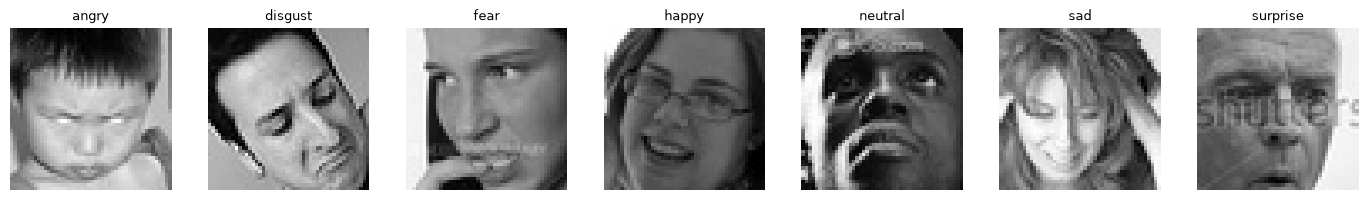

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 7, figsize=(14, 2))
for emotion_idx, ax in enumerate(axes):
    sample_idx = np.where(train_labels == emotion_idx)[0][0]
    ax.imshow(train_images[sample_idx], cmap="gray")
    ax.set_title(EMOTIONS[emotion_idx], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("checkpoints_sample_grid.png")
print("saved checkpoints_sample_grid.png")

## 2. Dataset Class, Augmentation, Train/Val Split

Wraps the numpy arrays in a `torch.utils.data.Dataset`, applies data
augmentation (flip/rotation/translation) only to the training split, and
carves a validation set out of the training data.

In [4]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms

torch.manual_seed(42)
np.random.seed(42)


class FERDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = torch.from_numpy(self.images[idx]).float().div(255.0).unsqueeze(0)  # (1, 48, 48)
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.labels[idx])


train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
])

/opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/lib/python3.11/site-packages/torchvision/io/image.py:14: UserWarning: Failed to load image Python extension: 'dlopen(/opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/lib/python3.11/site-packages/torchvision/image.so, 0x0006): Library not loaded: @rpath/libjpeg.9.dylib
  Referenced from: <EB3FF92A-5EB1-3EE8-AF8B-5923C1265422> /opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/lib/python3.11/site-packages/torchvision/image.so
  Reason: tried: '/opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/lib/python3.11/lib-dynload/../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniforge/base/envs/fer-capstone/bin/../lib/libjpeg.9.dylib'

In [5]:
rng = np.random.default_rng(42)
n = len(train_labels)
perm = rng.permutation(n)
val_size = int(0.1 * n)
val_idx, train_idx = perm[:val_size], perm[val_size:]

train_ds = FERDataset(train_images[train_idx], train_labels[train_idx], transform=train_transform)
val_ds = FERDataset(train_images[val_idx], train_labels[val_idx], transform=None)
test_ds = FERDataset(test_images, test_labels, transform=None)

print("train_ds:", len(train_ds), "val_ds:", len(val_ds), "test_ds:", len(test_ds))
assert len(train_ds) + len(val_ds) == n
assert len(test_ds) == 7178

sample_img, sample_label = train_ds[0]
assert sample_img.shape == (1, 48, 48), sample_img.shape
assert sample_img.dtype == torch.float32
assert 0.0 <= sample_img.min() and sample_img.max() <= 1.0
print("sample OK:", sample_img.shape, sample_img.dtype, sample_label)

train_ds: 25839 val_ds: 2870 test_ds: 7178
sample OK: torch.Size([1, 48, 48]) torch.float32 0


## 3. Model Definition

A small CNN: three Conv-BatchNorm-ReLU blocks with max-pooling, then a
dropout + fully-connected classifier head over the 7 emotion classes.
`block3` is kept as a named submodule so Grad-CAM (Task 8) can hook it.

In [6]:
import torch.nn as nn


class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )  # -> (32, 24, 24)
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )  # -> (64, 12, 12)
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
        )  # -> (128, 12, 12) -- Grad-CAM hooks this block's output
        self.pool3 = nn.MaxPool2d(2)  # -> (128, 6, 6)
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(128 * 6 * 6, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.pool3(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

In [7]:
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
try:
    _probe = torch.zeros(2, 1, 48, 48, device=device)
    EmotionCNN().to(device)(_probe)
except RuntimeError as e:
    print(f"mps backend errored ({e}); falling back to cpu")
    device = torch.device("cpu")
print("using device:", device)

model = EmotionCNN().to(device)
dummy = torch.randn(4, 1, 48, 48, device=device)
out = model(dummy)
print("output shape:", out.shape)
assert out.shape == (4, 7)

using device: mps
output shape: torch.Size([4, 7])


## 4. Training / Evaluation Functions

Standard train/eval epoch loops, smoke-tested on a small subset before
committing to the full run in the next section.

In [8]:
from torch.utils.data import DataLoader


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total

In [9]:
smoke_train = torch.utils.data.Subset(train_ds, range(500))
smoke_val = torch.utils.data.Subset(val_ds, range(100))
smoke_train_loader = DataLoader(smoke_train, batch_size=32, shuffle=True)
smoke_val_loader = DataLoader(smoke_val, batch_size=32)

smoke_model = EmotionCNN().to(device)
smoke_optimizer = torch.optim.Adam(smoke_model.parameters(), lr=1e-3)
smoke_criterion = nn.CrossEntropyLoss()

losses = []
for epoch in range(2):
    loss, acc = train_one_epoch(smoke_model, smoke_train_loader, smoke_optimizer, smoke_criterion, device)
    val_loss, val_acc = evaluate(smoke_model, smoke_val_loader, smoke_criterion, device)
    losses.append(loss)
    print(f"[smoke] epoch {epoch}: train_loss={loss:.3f} train_acc={acc:.3f} val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

assert losses[-1] < losses[0], "loss did not decrease on smoke test — check the training loop"
print("smoke test passed: loss decreased")

[smoke] epoch 0: train_loss=2.201 train_acc=0.180 val_loss=1.901 val_acc=0.140


[smoke] epoch 1: train_loss=1.797 train_acc=0.218 val_loss=1.889 val_acc=0.210
smoke test passed: loss decreased


## 5. Full Training Run

Trains the real model for 20 epochs, saves a checkpoint, and plots
loss/accuracy curves.

In [10]:
import os

os.makedirs("checkpoints", exist_ok=True)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=128)

model = EmotionCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

EPOCHS = 20
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"epoch {epoch+1}/{EPOCHS}: train_loss={train_loss:.3f} train_acc={train_acc:.3f} "
          f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

torch.save(model.state_dict(), "checkpoints/model.pt")
print("saved checkpoints/model.pt")

epoch 1/20: train_loss=1.806 train_acc=0.252 val_loss=1.651 val_acc=0.308


epoch 2/20: train_loss=1.676 train_acc=0.318 val_loss=1.631 val_acc=0.339


epoch 3/20: train_loss=1.607 train_acc=0.362 val_loss=1.457 val_acc=0.446


epoch 4/20: train_loss=1.556 train_acc=0.390 val_loss=1.487 val_acc=0.406


epoch 5/20: train_loss=1.524 train_acc=0.400 val_loss=1.363 val_acc=0.477


epoch 6/20: train_loss=1.501 train_acc=0.411 val_loss=1.370 val_acc=0.470


... (10 outputs left out)

epoch 17/20: train_loss=1.392 train_acc=0.453 val_loss=1.256 val_acc=0.513


epoch 18/20: train_loss=1.380 train_acc=0.455 val_loss=1.267 val_acc=0.520


epoch 19/20: train_loss=1.374 train_acc=0.461 val_loss=1.243 val_acc=0.530


epoch 20/20: train_loss=1.370 train_acc=0.461 val_loss=1.227 val_acc=0.529
saved checkpoints/model.pt


saved checkpoints/training_curves.png


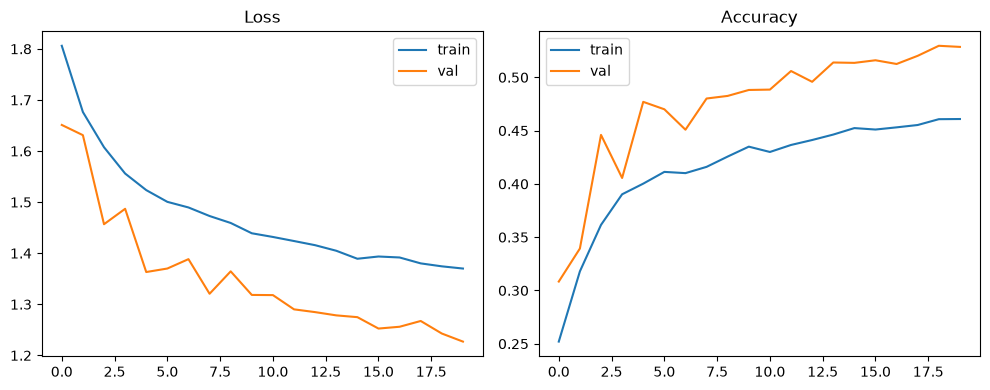

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig("checkpoints/training_curves.png")
print("saved checkpoints/training_curves.png")

assert history["val_acc"][-1] > history["val_acc"][0], "val accuracy did not improve over training"

## 6. Evaluation on Test Set

Test accuracy, per-class precision/recall/F1, and a confusion matrix —
important given FER-2013's class imbalance (rare `disgust` class).

test accuracy: 0.531
              precision    recall  f1-score   support

       angry       0.41      0.34      0.37       958
     disgust       0.00      0.00      0.00       111
        fear       0.31      0.11      0.17      1024
       happy       0.78      0.83      0.80      1774
     neutral       0.46      0.58      0.52      1233
         sad       0.36      0.44      0.39      1247
    surprise       0.62      0.77      0.69       831

    accuracy                           0.53      7178
   macro avg       0.42      0.44      0.42      7178
weighted avg       0.50      0.53      0.51      7178

saved checkpoints/confusion_matrix.png


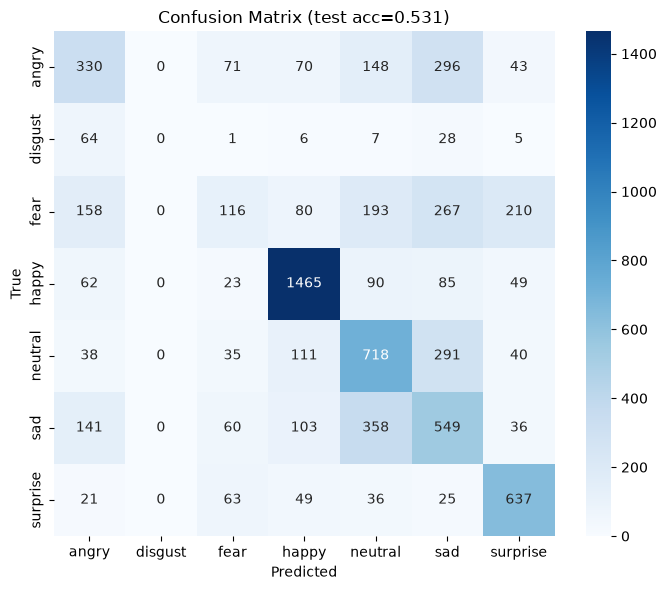

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_loader = DataLoader(test_ds, batch_size=128)

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        preds = model(images).argmax(dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())

test_acc = sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels)
print(f"test accuracy: {test_acc:.3f}")
assert 0.0 < test_acc < 1.0

print(classification_report(all_labels, all_preds, target_names=EMOTIONS, zero_division=0))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=EMOTIONS, yticklabels=EMOTIONS, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion Matrix (test acc={test_acc:.3f})")
plt.tight_layout()
plt.savefig("checkpoints/confusion_matrix.png")
print("saved checkpoints/confusion_matrix.png")

## 7. Explainability — Grad-CAM and Saliency Maps

Grad-CAM (via a hook on `model.block3`, the last conv block) and a
vanilla input-gradient saliency map, for one sample per emotion class.

**Known limitation:** the classification report above shows the model
never predicts `disgust` (0.00 precision/recall) — it is the rarest
class by far (~1.7% of training data). This is an expected consequence
of FER-2013's class imbalance for a simple CNN with no class weighting
or resampling, not a bug in the pipeline (see ADR 0001, out of scope to
fix here).

In [13]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        score = output[0, class_idx]
        score.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = cam[0, 0]
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu().numpy()


def compute_saliency(model, input_tensor, class_idx):
    input_tensor = input_tensor.clone().requires_grad_(True)
    model.zero_grad()
    output = model(input_tensor)
    score = output[0, class_idx]
    score.backward()
    saliency = input_tensor.grad.abs()[0, 0]
    saliency = saliency - saliency.min()
    if saliency.max() > 0:
        saliency = saliency / saliency.max()
    return saliency.detach().cpu().numpy()

saved checkpoints/explainability.png


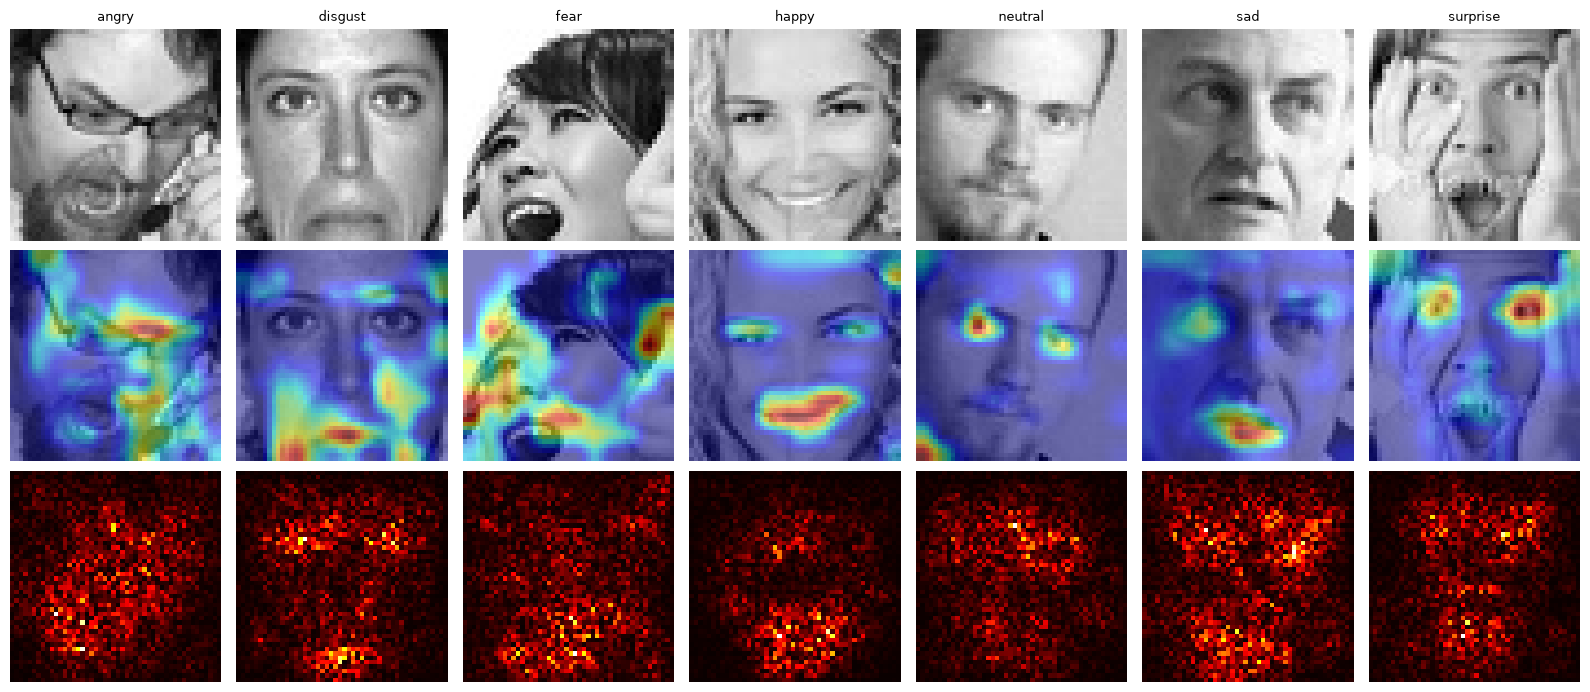

In [14]:
from PIL import Image as PILImage


def resize_map(arr_2d, size=(48, 48)):
    img = PILImage.fromarray((arr_2d * 255).astype(np.uint8))
    img = img.resize(size, PILImage.BILINEAR)
    return np.array(img, dtype=np.float32) / 255.0


gradcam = GradCAM(model, model.block3)

fig, axes = plt.subplots(3, 7, figsize=(16, 7))
for col, emotion_idx in enumerate(range(7)):
    sample_idx = int(np.where(test_ds.labels == emotion_idx)[0][0])
    img_tensor, label = test_ds[sample_idx]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    cam = gradcam.generate(input_tensor, class_idx=label)
    cam_resized = resize_map(cam)
    assert cam_resized.std() > 1e-6, f"Grad-CAM heatmap is degenerate for {EMOTIONS[emotion_idx]}"

    saliency = compute_saliency(model, input_tensor, class_idx=label)
    assert saliency.std() > 1e-6, f"saliency map is degenerate for {EMOTIONS[emotion_idx]}"

    face = img_tensor[0].numpy()
    axes[0, col].imshow(face, cmap="gray")
    axes[0, col].set_title(EMOTIONS[emotion_idx], fontsize=9)
    axes[0, col].axis("off")
    axes[1, col].imshow(face, cmap="gray")
    axes[1, col].imshow(cam_resized, cmap="jet", alpha=0.5)
    axes[1, col].axis("off")
    axes[2, col].imshow(saliency, cmap="hot")
    axes[2, col].axis("off")

axes[0, 0].set_ylabel("input", fontsize=9)
axes[1, 0].set_ylabel("Grad-CAM", fontsize=9)
axes[2, 0].set_ylabel("saliency", fontsize=9)
plt.tight_layout()
plt.savefig("checkpoints/explainability.png")
print("saved checkpoints/explainability.png")